![digitizing_team](digitizing_team.png)


DigiNsure Inc. is an innovative insurance company focused on enhancing the efficiency of processing claims and customer service interactions. Their newest initiative is digitizing all historical insurance claim documents, which includes improving the labeling of some IDs scanned from paper documents and identifying them as primary or secondary IDs.

To help them in their effort, you'll be using multi-modal learning to train an Optical Character Recognition (OCR) model. To improve the classification, the model will use **images** of the scanned documents as input and their **insurance type** (home, life, auto, health, or other). Integrating different data modalities (such as image and text) enables the model to perform better in complex scenarios, helping to capture more nuanced information. The **labels** that the model will be trained to identify are of two types: a primary and a secondary ID, for each image-insurance type pair.

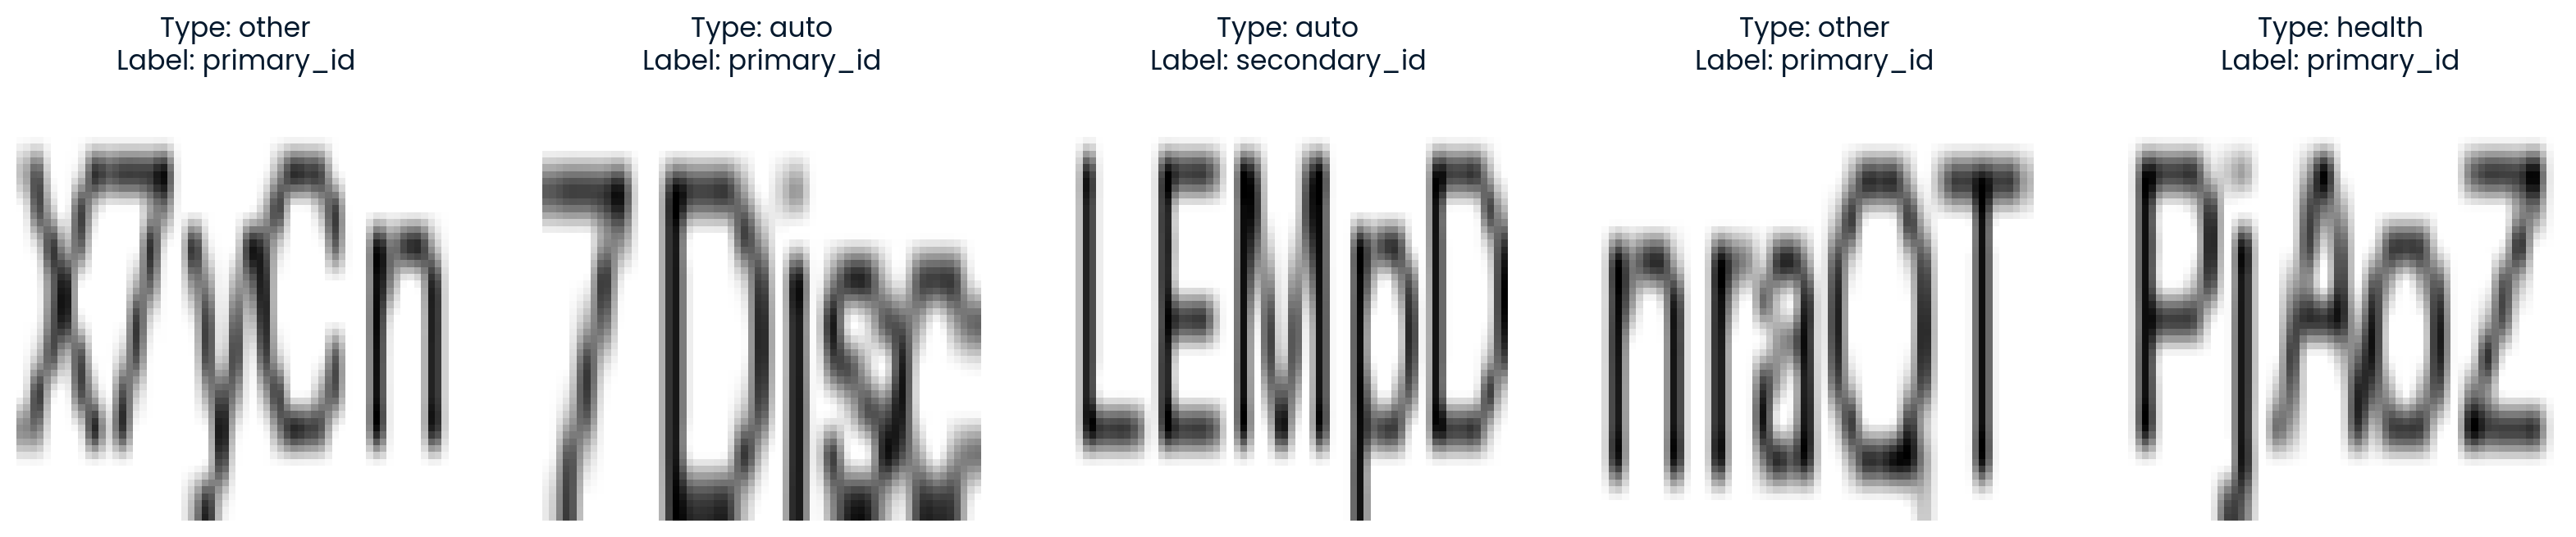

In [8]:
# Import the necessary libraries
import matplotlib.pyplot as plt
import numpy as np
from project_utils import ProjectDataset
import pickle 
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

# Load the data
dataset = pickle.load(open('ocr_insurance_dataset.pkl', 'rb'))

# Define a function to visualize codes with their corresponding types and labels 
def show_dataset_images(dataset, num_images=5):
    fig, axes = plt.subplots(1, min(num_images, len(dataset)), figsize=(20, 4))
    for ax, idx in zip(axes, np.random.choice(len(dataset), min(num_images, len(dataset)), False)):
        img, lbl = dataset[idx]
        ax.imshow((img[0].numpy() * 255).astype(np.uint8).reshape(64,64), cmap='gray'), ax.axis('off')
        ax.set_title(f"Type: {list(dataset.type_mapping.keys())[img[1].tolist().index(1)]}\nLabel: {list(dataset.label_mapping.keys())[list(dataset.label_mapping.values()).index(lbl)]}")
    plt.show()

# Inspect 5 codes images from the dataset
show_dataset_images(dataset)

In [9]:
# Start coding here
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Step 1: Defining the OCRModel class
class OCRModel(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        
        # Image Branch: Conv2d (1 in, 16 out, kernel 3x3, padding 1) -> ReLU -> MaxPool -> Linear
        self.image_layer = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
            nn.Flatten(),
            nn.Linear(16 * 32 * 32, 128)
        )
        
        # Type Branch
        self.type_layer = nn.Sequential(
            nn.Linear(5, 10),
            nn.ReLU()
        )
        
        # Classifier on combined features (128 + 10 -> num_classes)
        self.classifier = nn.Sequential(
            nn.Linear(128 + 10, num_classes)
        )

    def forward(self, x_image, x_type):
        x_image = self.image_layer(x_image)
        x_type = self.type_layer(x_type)
        x = torch.cat((x_image, x_type), dim=1)
        return self.classifier(x)

# Instantiate model, optimizer, loss function, and dataloader
# (Set num_classes to match len(dataset.label_mapping))
num_classes = len(dataset.label_mapping) if hasattr(dataset, 'label_mapping') else 2
model = OCRModel(num_classes=num_classes)

optimizer = optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()
dataloader = DataLoader(dataset, batch_size=16, shuffle=True)

# Step 2: Training loop for 10 epochs
num_epochs = 10
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    
    for (batch_images, batch_types), batch_labels in dataloader:
        optimizer.zero_grad()
        outputs = model(batch_images, batch_types)
        loss = criterion(outputs, batch_labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        
    epoch_loss = running_loss / len(dataloader)
    print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}")

Epoch 1/10, Loss: 7.9460
Epoch 2/10, Loss: 3.4253
Epoch 3/10, Loss: 2.6708
Epoch 4/10, Loss: 1.1700
Epoch 5/10, Loss: 0.6288
Epoch 6/10, Loss: 0.6036
Epoch 7/10, Loss: 0.5507
Epoch 8/10, Loss: 0.5909
Epoch 9/10, Loss: 0.5006
Epoch 10/10, Loss: 0.4256
